In [12]:
import os
from langchain.agents import create_agent
from typing import List, Literal
from pydantic import BaseModel, Field
#from langchain_core.tools import tool -? used for @tool
from langchain_core.tools import Tool
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
from langchain_astradb import AstraDBVectorStore
from langchain_groq import ChatGroq
from langchain_community.document_loaders import WebBaseLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langgraph.graph import END,START
from langgraph.graph import StateGraph
from typing import Annotated, TypedDict, Sequence
from langchain_core.messages import BaseMessage, HumanMessage, AIMessage
from langgraph.graph.message import add_messages
from langchain_community.document_loaders import TextLoader
from pydantic import BaseModel
from typing import List
from langchain_core.documents import Document



In [ ]:
from dotenv import load_dotenv
load_dotenv()

os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")

ASTRA_DB_API_ENDPOINT = ""
ASTRA_DB_APPLICATION_TOKEN = ""

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

vector_store = AstraDBVectorStore(
    collection_name="autonomous_agent",
    embedding=embeddings,
    api_endpoint=ASTRA_DB_API_ENDPOINT,
    token=ASTRA_DB_APPLICATION_TOKEN,
    namespace=None,
)


llm = ChatGroq(
    model="qwen/qwen3.8-27b",
    max_tokens=200,
    temperature=0
)

retriever = vector_store.as_retriever()

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3402.97it/s]


In [14]:
# -------------------------
# 2. State Definition
# -------------------------
class RAGReflectionState(BaseModel):
    question: str
    retrieved_docs: List[Document] = []
    answer: str = ""
    reflection: str = ""
    revised: bool = False
    attempts: int = 0

In [15]:
# -------------------------
# 3. Nodes
# -------------------------

# a. Retrieve
def retrieve_docs(state: RAGReflectionState) -> RAGReflectionState:
    docs = retriever.invoke(state.question)
    return state.model_copy(update={"retrieved_docs": docs})

# b. Generate Answer
def generate_answer(state: RAGReflectionState) -> RAGReflectionState:
    
    context = "\n\n".join([doc.page_content for doc in state.retrieved_docs])
    prompt = f"""
Use the following context to answer the question:

Context:
{context}

Question:
{state.question}
"""
    answer = llm.invoke(prompt).content.strip()
    return state.model_copy(update={"answer": answer, "attempts": state.attempts + 1})

In [16]:
# c. Self-Reflect
def reflect_on_answer(state: RAGReflectionState) -> RAGReflectionState:
    
    prompt = f"""
Reflect on the following answer to see if it fully addresses the question. 
State YES if it is complete and correct, or NO with an explanation.

Question: {state.question}

Answer: {state.answer}

Respond like:
Reflection: YES or NO
Explanation: ...
"""
    result = llm.invoke(prompt).content
    is_ok = "reflection: yes" in result.lower()
    return state.model_copy(update={"reflection": result, "revised": not is_ok})

In [17]:
# d. Finalizer
def finalize(state: RAGReflectionState) -> RAGReflectionState:
    return state

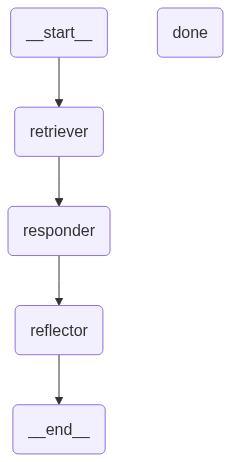

In [18]:
# -------------------------
# 4. LangGraph DAG
# -------------------------
builder = StateGraph(RAGReflectionState)

builder.add_node("retriever", retrieve_docs)
builder.add_node("responder", generate_answer)
builder.add_node("reflector", reflect_on_answer)
builder.add_node("done", finalize)

builder.set_entry_point("retriever")

builder.add_edge("retriever", "responder")
builder.add_edge("responder", "reflector")
builder.add_conditional_edges(
    "reflector",
    lambda s: "done" if not s.revised or s.attempts >= 2 else "retriever"
)

builder.add_edge("done", END)
graph = builder.compile()
graph

In [19]:
# -------------------------
# 5. Run the Agent
# -------------------------
if __name__ == "__main__":
    user_query = "What are the transformer variants in production deployments?"
    init_state = RAGReflectionState(question=user_query)
    result = graph.invoke(init_state)

    print("\n🧠 Final Answer:\n", result["answer"])
    print("\n🔁 Reflection Log:\n", result["reflection"])
    print("🔄 Total Attempts:", result["attempts"])


🧠 Final Answer:
 Based on the provided experiment log, the only transformer variant explicitly identified as having a specific **deployment target** is **EfficientFormer**.

*   **EfficientFormer**: Listed with a "Deployment target: Raspberry Pi 4" and notes that it "Works well in quantized int8 mode."

The other models mentioned (Longformer, TinyBERT, Reformer, LLaMA2 with FlashAttention2) are described in terms of evaluation metrics, experimental integrations, or training challenges, but none are explicitly stated to be in "production deployment" in the same direct manner as EfficientFormer.

Therefore, the transformer variant in production deployment is **EfficientFormer**.

🔁 Reflection Log:
 Reflection: NO
Explanation: The answer incorrectly assumes that "deployment target" (Raspberry Pi 4) equates to "production deployment." In technical contexts, a deployment target often refers to the intended hardware for testing, edge prototyping, or specific use cases, not necessarily a liv

### Below is more correct as per ChatGpt

In [ ]:



# ----------------------------------
# 1. Define Shared State
# ----------------------------------

class RAGReflectionState(BaseModel):
    question: str
    retrieved_docs: List[Document] = Field(default_factory=list)
    answer: str = ""
    reflection: str = ""
    needs_revision: bool = False
    attempts: int = 0
    retrieval_query: str = ""
    approved: bool = False


# ----------------------------------
# 2. Structured Reflection Output
# ----------------------------------

class ReflectionResult(BaseModel):
    verdict: Literal["YES", "NO"]
    explanation: str


structured_reflector = llm.with_structured_output(
    ReflectionResult
)


# ----------------------------------
# 3. Node 1: Retrieve Documents
# ----------------------------------

def retrieve_docs(state: RAGReflectionState):

    # First attempt uses original question.
    # Later attempts use an improved retrieval query.
    query = state.retrieval_query or state.question

    docs = retriever.invoke(query)

    # Retain evidence from earlier attempts.
    all_docs = state.retrieved_docs + docs

    # Remove duplicate documents.
    unique_docs = []
    seen = set()

    for doc in all_docs:
        key = (doc.page_content, repr(doc.metadata))

        if key not in seen:
            seen.add(key)
            unique_docs.append(doc)

    return {
        "retrieved_docs": unique_docs
    }


# ----------------------------------
# 4. Node 2: Generate / Revise Answer
# ----------------------------------

def generate_answer(state: RAGReflectionState):

    context = "\n\n".join(
        doc.page_content
        for doc in state.retrieved_docs
    )

    prompt = f"""
You are a retrieval-augmented assistant.

Original Question:
{state.question}

Retrieved Context:
{context}

Previous Answer:
{state.answer}

Previous Reflection:
{state.reflection}

Instructions:
1. Answer the original question using retrieved evidence.
2. If reflection feedback exists, address the identified issues.
3. Do not invent unsupported facts.
4. If the evidence is insufficient, explicitly say so.
5. Produce a clear and complete final answer.

Answer:
"""

    response = llm.invoke(prompt)

    return {
        "answer": response.content.strip(),
        "attempts": state.attempts + 1
    }


# ----------------------------------
# 5. Node 3: Self-Reflection
# ----------------------------------

def reflect_on_answer(state: RAGReflectionState):

    context = "\n\n".join(
        doc.page_content
        for doc in state.retrieved_docs
    )

    prompt = f"""
You are an independent answer evaluator.

Original Question:
{state.question}

Retrieved Evidence:
{context}

Generated Answer:
{state.answer}

Evaluate:
1. Does the answer address the question?
2. Is it supported by retrieved evidence?
3. Are important details missing?
4. Does it contain unsupported claims?

Return:
- verdict = YES if sufficiently complete and grounded.
- verdict = NO if revision is required.
- explanation = specific feedback.

Do not approve unsupported claims.
"""

    result = structured_reflector.invoke(prompt)

    return {
        "reflection": result.explanation,
        "needs_revision": result.verdict == "NO",
        "approved": result.verdict == "YES"
    }


# ----------------------------------
# 6. Node 4: Improve Retrieval Query
# ----------------------------------

def improve_query(state: RAGReflectionState):

    prompt = f"""
Rewrite the retrieval query to find evidence
missing from the previous answer.

Original Question:
{state.question}

Previous Answer:
{state.answer}

Evaluation Feedback:
{state.reflection}

Return only one improved search query.
Do not answer the question.
"""

    query = llm.invoke(prompt).content.strip()

    return {
        "retrieval_query": query
    }


# ----------------------------------
# 7. Conditional Routing
# ----------------------------------

MAX_ATTEMPTS = 2


def route_after_reflection(state: RAGReflectionState):

    if not state.needs_revision:
        return "done"

    if state.attempts >= MAX_ATTEMPTS:
        return "done"

    return "improve_query"


# ----------------------------------
# 8. Finalizer
# ----------------------------------

def finalize(state: RAGReflectionState):

    # Keep final answer and evaluation status.
    return {}


# ----------------------------------
# 9. Build LangGraph
# ----------------------------------

builder = StateGraph(RAGReflectionState)

builder.add_node("retriever", retrieve_docs)
builder.add_node("responder", generate_answer)
builder.add_node("reflector", reflect_on_answer)
builder.add_node("improve_query", improve_query)
builder.add_node("done", finalize)

builder.add_edge(START, "retriever")

builder.add_edge("retriever", "responder")
builder.add_edge("responder", "reflector")

builder.add_conditional_edges(
    "reflector",
    route_after_reflection,
    {
        "done": "done",
        "improve_query": "improve_query"
    }
)

builder.add_edge("improve_query", "retriever")
builder.add_edge("done", END)

graph = builder.compile()


# ----------------------------------
# 10. Execute
# ----------------------------------

if __name__ == "__main__":

    user_query = (
        "What are the transformer variants "
        "in production deployments?"
    )

    initial_state = RAGReflectionState(
        question=user_query
    )

    result = graph.invoke(initial_state)

    print("\nFINAL ANSWER:\n")
    print(result["answer"])

    print("\nREFLECTION FEEDBACK:\n")
    print(result["reflection"])

    print("\nAPPROVED:", result["approved"])
    print("TOTAL ATTEMPTS:", result["attempts"])

    if not result["approved"]:
        print(
            "\nWARNING: The answer did not pass "
            "reflection within the retry limit."
        )



FINAL ANSWER:

Based on the retrieved experiment log, the evidence is **insufficient** to definitively list which transformer variants are currently in "production deployments." The log primarily documents evaluation metrics, experimental results, and training challenges rather than confirming active production status for most models.

However, based on the specific language used in the log, here is the breakdown of the models and their stated status:

1.  **EfficientFormer**: The log explicitly states a **"Deployment target: Raspberry Pi 4"** and notes it "Works well in quantized int8 mode." This is the strongest evidence of a deployment intent or active deployment in the provided text.
2.  **TinyBERT**: The log states it is **"Used for classification: Support ticket priority tagging."** The use of the present tense "Used for" suggests it is actively being applied to this task, which may imply production use, though it is not explicitly labeled as "production."
3.  **LLaMA2**: The

R

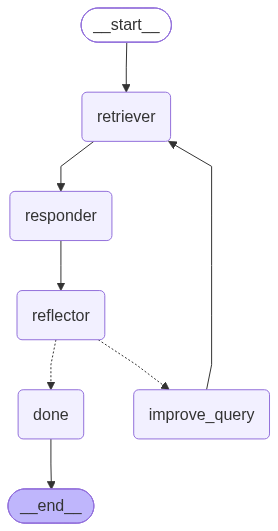

In [22]:
graph

Above is called as Iterative Retrieval in Agentic RAG